## 导入库和预训练的模型

In [5]:
import torch
import torchvision.models as models
import torchvision.transforms as transforms

In [4]:
model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
model.eval()

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\34854/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100%|██████████| 528M/528M [01:57<00:00, 4.73MB/s] 


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

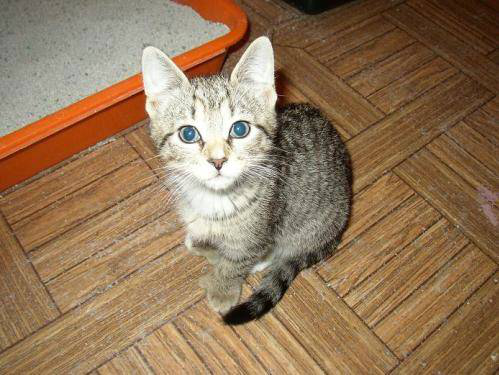

In [13]:
import yaml
import random
from PIL import Image
import os
import torchvision.datasets as datasets
with open('config.yaml', 'r', encoding='utf-8') as f:
    cfg = yaml.load(f, Loader=yaml.FullLoader)

train_path = cfg["train_root"]
raw_data = datasets.ImageFolder(train_path, transform=None)

random.seed(3)
idx = random.randint(0, len(raw_data)-1)
img_path, img_label = raw_data.samples[idx]
raw_img = Image.open(img_path).convert('RGB')
display(raw_img)

In [14]:
transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

img = Image.open(img_path).convert('RGB')
x = transform(img)
x = x.unsqueeze(0)

In [17]:
with torch.no_grad():
    logits_shallow = model.features[0](x)
    h = logits_shallow

    for i in range (1, 29):
        h = model.features[i](h)
    logits_deep = h

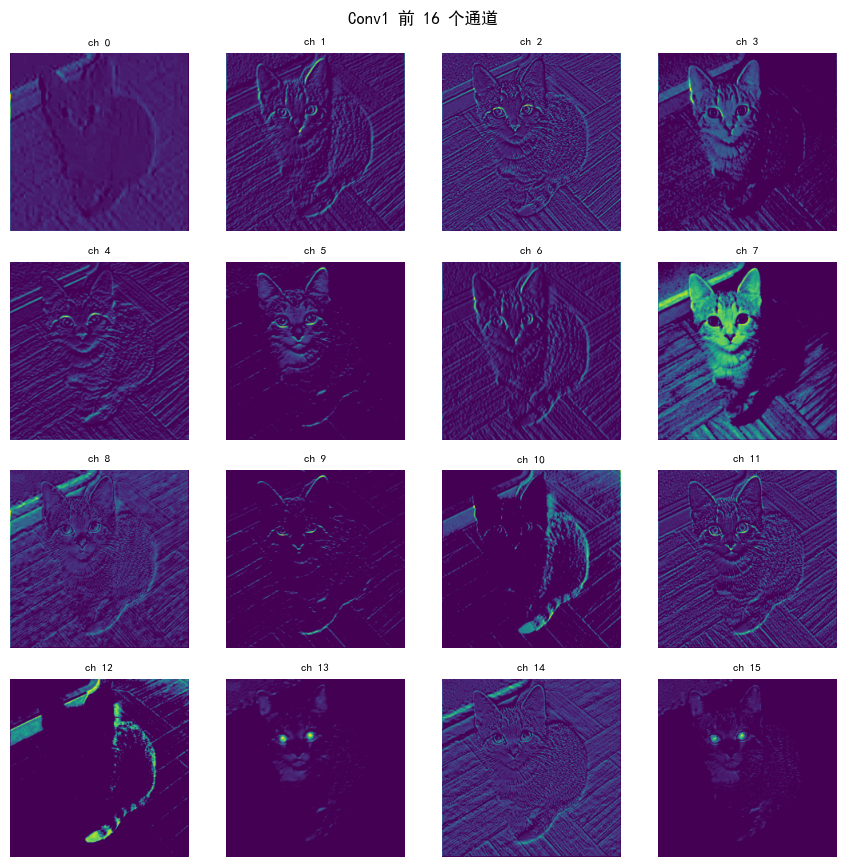

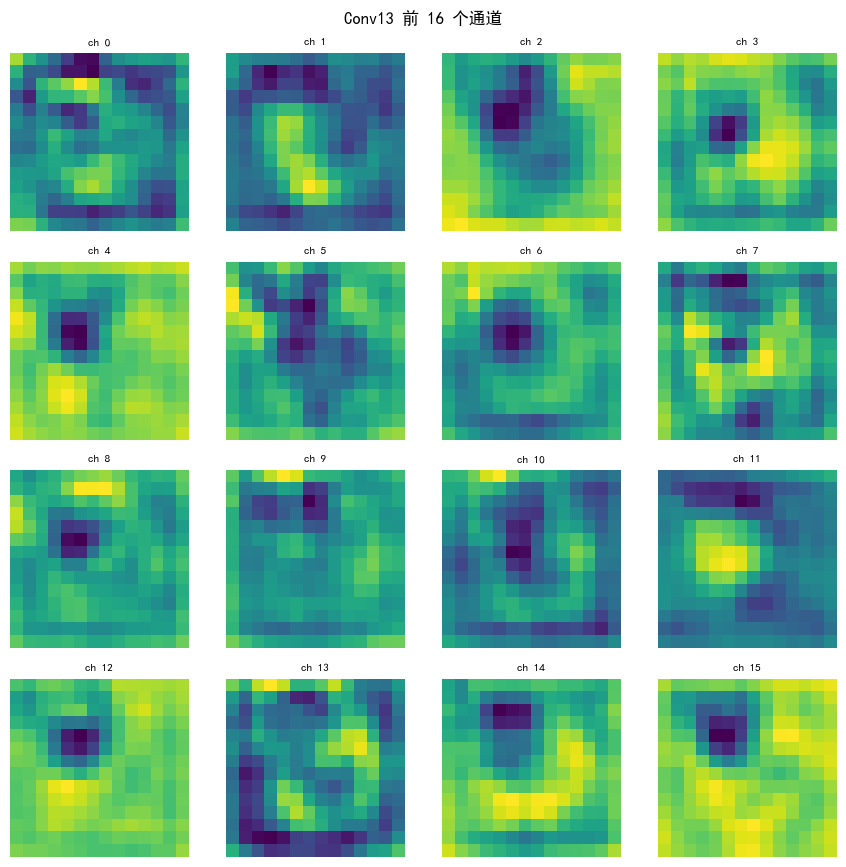

In [22]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'PingFang SC']
plt.rcParams['axes.unicode_minus'] = False

def show_feature_maps(feat, n_channels=16, ncols=4, title=""):
    f = feat[0].cpu().numpy()          # (c, h, w)
    n = min(n_channels, f.shape[0])
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 2.2, nrows * 2.2))
    axes = np.array(axes).reshape(-1)  # 统一成 1D

    for i in range(n):
        m = f[i]
        m = (m - m.min()) / (m.max() - m.min() + 1e-8)   # 单通道归一化
        axes[i].imshow(m, cmap="viridis")
        axes[i].set_title(f"ch {i}", fontsize=8)
        axes[i].axis("off")
    for i in range(n, len(axes)):
        axes[i].axis("off")

    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

show_feature_maps(logits_shallow, n_channels=16, ncols=4,
                  title="Conv1 前 16 个通道")
show_feature_maps(logits_deep, n_channels=16, ncols=4,
                  title="Conv13 前 16 个通道")

In [28]:
l2_shallow = logits_shallow.pow(2).sum(dim=(2, 3)).sqrt()
l2_deep = logits_deep.pow(2).sum(dim=(2, 3)).sqrt()
print(l2_shallow[0, 5])
print(l2_shallow)
print(l2_deep)

tensor(36.4097)
tensor([[137.4216, 202.0915, 169.8651,  74.9207, 237.3064,  36.4097, 231.6144,
         118.7537,  82.6053,  56.6162,  67.3153,  95.0959,  47.0502,  18.4135,
         134.2280,  15.0512, 132.7211,  45.3832,  65.5552, 185.1896, 161.6675,
         148.6558, 101.7091,  92.2896,  39.2482,  50.8610,  20.1683,  23.8192,
          46.4988,  64.8413,  35.3064,  60.5119,  95.2106, 122.2950, 171.9664,
          19.7833,  54.9969,  10.3566,  40.8522, 107.8622, 151.0287,  80.9516,
         175.5765,  44.9885,  25.1178,  65.4247,  66.5129, 194.4877,  76.3649,
          20.9633,  12.9286, 159.7263,  51.7873, 146.1498,  55.2493, 145.1100,
         141.1023, 279.0127, 250.6668, 160.1841,  92.0889, 115.0275,   8.9835,
         142.3664]])
tensor([[ 97.4694,  76.1760,  82.8049, 147.8040, 169.2452, 133.9220, 155.1543,
         108.8491, 145.0632, 116.9991, 118.9149,  56.6052,  94.9471, 136.6510,
         128.9830, 120.0619, 105.2657, 117.4286, 159.3533, 117.2858,  90.1316,
          73.25

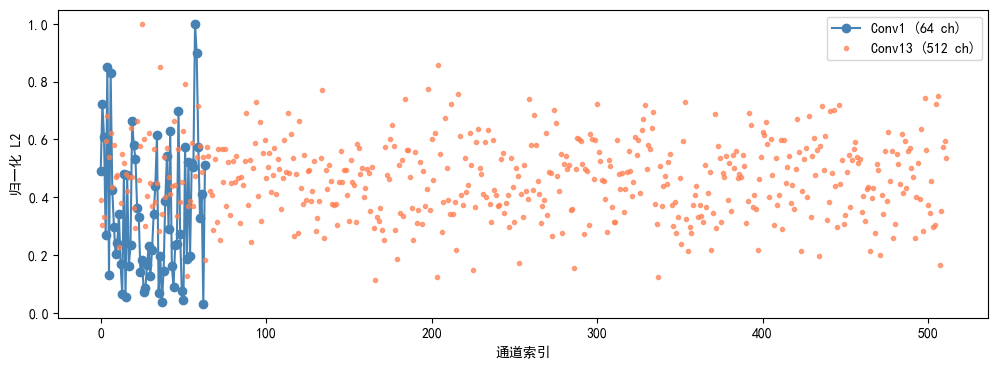

In [30]:
# 归一化后用同一个尺度对比
l2s_norm = (l2_shallow[0] / l2_shallow.max()).cpu().numpy()
l2d_norm = (l2_deep[0]    / l2_deep.max()).cpu().numpy()

plt.figure(figsize=(12, 4))
plt.plot(np.arange(64),  l2s_norm, 'o-', color="steelblue", label="Conv1 (64 ch)")
plt.plot(np.arange(512), l2d_norm, '.',  color="coral",     label="Conv13 (512 ch)", alpha=0.7)
plt.xlabel("通道索引"); plt.ylabel("归一化 L2"); plt.legend()
plt.show()